In [19]:
import numpy as np

loaded_data = np.load('spiral_data.npz')

# Extract the arrays using the keys defined during export
K = loaded_data['K'].item()
x_train = loaded_data['x']
y_train = loaded_data['y']

In [37]:
%matplotlib inline

In [20]:
%run ./functions.ipynb

In [25]:
import itertools
#small number of epochs for testing
N_epochs = 1000
learning_rate=[0.1, 0.5, 1.0, 2.0]
#make set of possible hidden layers given range of number of hidden layers (pos_len) and possible size of each hidden layer (pos_size)
pos_len    = [2, 3]
pos_size   = [4, 8]
all_arrays = []
for length in pos_len:
    # repeat=length tells it how many items to pick for each combination
    for combo in itertools.product(pos_size, repeat=length):
        all_arrays.append(list(combo))


reward_list   = []
#init best reward as 0
top_reward=0
episode=0
#loop through different learning rates
for lr in learning_rate:
    # Loop through different activation functions
    for act in ('gauss', 'relu', 'sigmoid', 'softmax'):
        #loop through different hidden layer structures
        for mid_size_array in all_arrays:
                #get model variables
                model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
                    x_train, y_train, K, mid_size_array, lr, N_epochs, act
                )

                epoch_list    = []
                cost_training = []
                acc_training  = []

                ### Train for several epochs: ###
                for epoch in range(N_epochs):

                    optimizer.zero_grad()
                    NN_output = model(x_train_tensor) # Use the tensor returned by your setup function
                    cost = cost_func(NN_output, y_onehot)
                    cost.backward()
                    optimizer.step()

                    ### Update the plot and print results every 500 epochs: ###
                    if epoch % 100 == 0:
                        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
                        accuracy = np.mean(predicted_class == y_train)

                        epoch_list.append(epoch)
                        cost_training.append(cost.detach().numpy())
                        acc_training.append(accuracy)


                        ### Update the plot of the resulting classifier: ###
    #                   fig = plt.figure(2, figsize=(15,8))
    #                   fig.subplots_adjust(hspace=.3, wspace=.3)
    #                   plt.clf()

    #                    updatePlot(model,epoch_list,cost_training,acc_training)

                        #display.display(plt.gcf())
                        #print(f"[{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")
                        #Stop clearing the output on the very last step so the final plot stays visible
                        #if epoch < N_epochs - 100:
                        #    display.clear_output(wait=True)
                        # time.sleep(0.1)


                reward = rewardFN(acc_training,cost_training,0.25)
                params = {
                            'activation': act,
                            'learning_rate': lr,
                            'num_layers': len(mid_size_array) ,
                            'layer_sizes': mid_size_array
                        }

                if(reward > top_reward):
                    top_reward = reward
                    best_params=params

                print(f"Episode {episode+1:02d} | Reward: {reward:.4f} | Params: {params}")
                episode +=1
print("best params:", best_params, "top reward:", top_reward)
                #plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
                #            bbox={"facecolor":"white", "pad":5})


                #Dynamically name the file based on the activation function and mid_size_array
                #filename = f'spiral_results_{act}_{mid_size_array}.pdf'
                #plt.savefig(filename, bbox_inches="tight")

                #print(f"Saved {filename}")

                #print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} Training accuracy {accuracy:.6f}\n")
                #print("-" * 50)


Episode 01 | Reward: 0.5513 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 02 | Reward: 0.5533 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [4, 8]}
Episode 03 | Reward: 0.5796 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 04 | Reward: 0.5196 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [8, 8]}
Episode 05 | Reward: 0.5253 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 06 | Reward: 0.5395 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [4, 4, 8]}
Episode 07 | Reward: 0.5096 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [4, 8, 4]}
Episode 08 | Reward: 0.5527 | Params: {'activation': 'gauss', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [4, 8, 

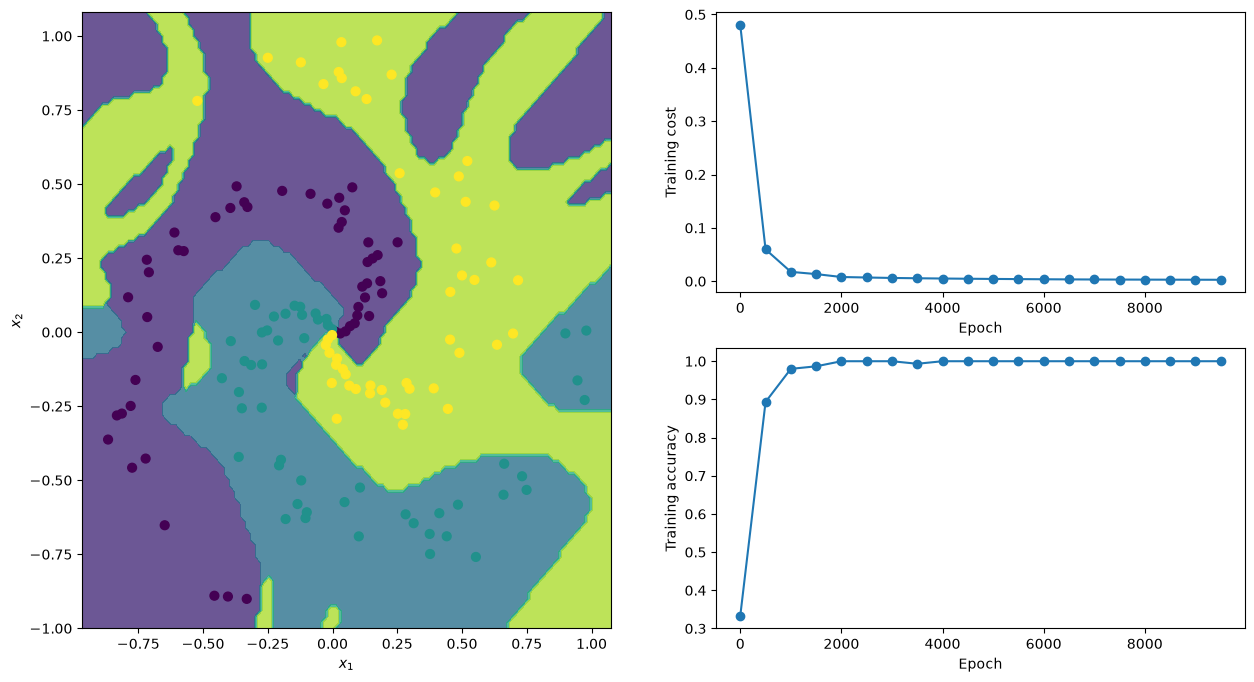

[GAUSS] Iteration 9500:
  Training cost 0.002760
  Training accuracy 1.000000

Saved spiral_results_gauss.pdf
Final GAUSS Training cost 0.002702
Final GAUSS Training accuracy 1.000000

--------------------------------------------------


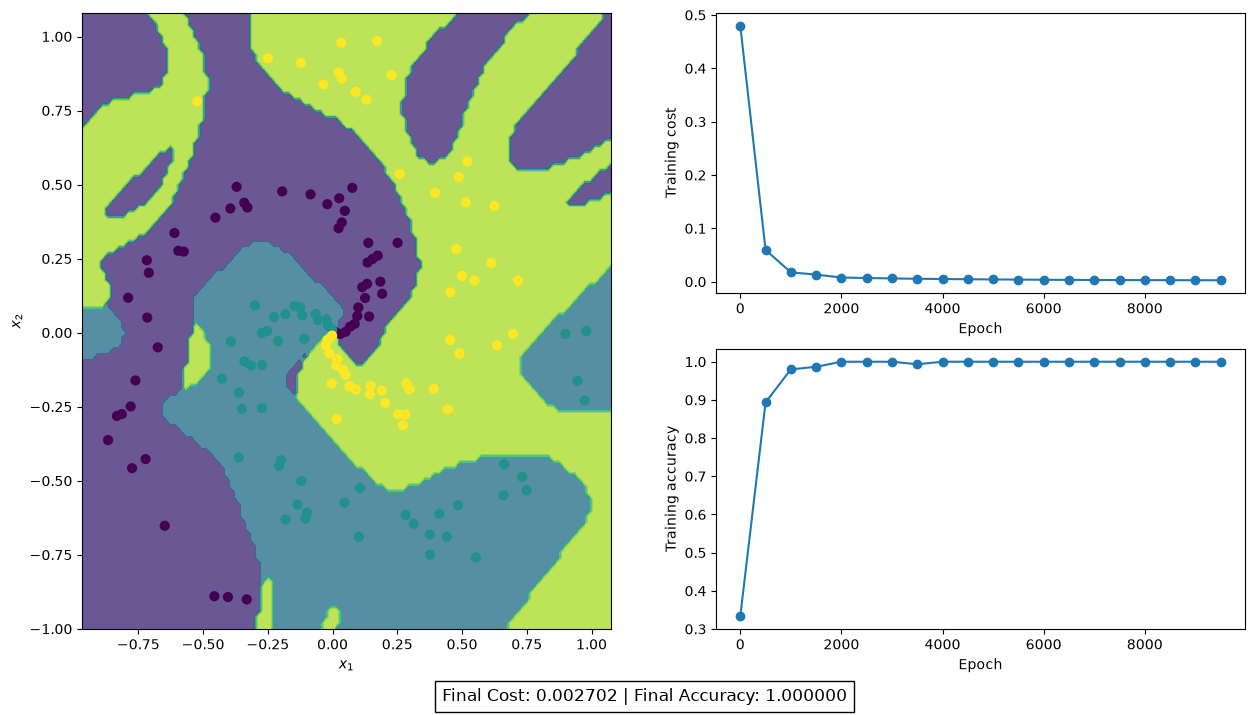

In [63]:
#test solution

N_epochs = 10000
act = best_params[0]
mid_size_array=best_params[1]
#get model variables
model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(x_train, y_train, K, mid_size_array, 1.0, N_epochs, act)

epoch_list    = []
cost_training = []
acc_training  = []

### Train for several epochs: ###
for epoch in range(N_epochs):

    optimizer.zero_grad()
    NN_output = model(x_train_tensor) # Use the tensor returned by your setup function
    cost = cost_func(NN_output, y_onehot)
    cost.backward()
    optimizer.step()

   ### Update the plot and print results every 500 epochs: ###
    if epoch % 500 == 0:
        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
        accuracy = np.mean(predicted_class == y_train)

        epoch_list.append(epoch)
        cost_training.append(cost.detach().numpy())
        acc_training.append(accuracy)

        ### Update the plot of the resulting classifier: ###
        fig = plt.figure(2, figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()

        updatePlot(model,epoch_list,cost_training,acc_training)

        display.display(plt.gcf())
        print(f"[{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        #Stop clearing the output on the very last step so the final plot stays visible
        if epoch < N_epochs - 500:
            display.clear_output(wait=True)
                    # time.sleep(0.1)

    #
metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
            bbox={"facecolor":"white", "pad":5})

            #Dynamically name the file based on the activation function
filename = f'spiral_results_{act}.pdf'
plt.savefig(filename, bbox_inches="tight")

print(f"Saved {filename}")
print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} Training accuracy {accuracy:.6f}\n")
print("-" * 50)